# Partie 2  -  Résolution numérique d'équations ordinaires (f(x)  = 0)

### ATTENTION: 
>#### l'exercice 1 porte sur l'intégration numérique
>#### l'exercice 2 porte sur la résolution numérique d'une équation $f(x)= 0$
>#### Chacun des exerices comporte une partie théorique à faire sur les copies d'examen.

In [1]:
%matplotlib inline
%config InlineBackend.figure_format = 'retina'

import numpy as np
from scipy.integrate import quad
import matplotlib.pyplot as plt

---
## Exercice 1 : Itégration numérique
---

On souhaite construire une formule de quadrature numérique pour approcher l'intégrale d'une fonction $f$.
On propose de la chercher sous la forme 
$$
\int_m^n f(x) \, dx \approx f(0) + 10f(1) + f(2).
$$
où c'est plutôt $m, n$ qui sont les inconnues.

### Question 1-1: Partie théorique (à faire sur la copie)

**Question 1-1-1:** Déterminer les inconnues $m$, $n$ permmettant de définir cette formule de quadrature.

**Question 1-1-2:** Réécrire cette formule de quadrature sur l'intervalle $[-1, 1]$ et déterminer son ordre d'exactitude.

**Question 1-1-3:** En utilisant un résultat du cours, montrer qu'il existe une constante $C > 0$ indépendante 
de $h$ telle que pour tout f de classe $C^2$, et pour tout $t$ et $h$ tels que $t, t + h \in I \subset \mathbb{R}$  on ait 
$$
\left| \int_t^{t+h} f(x) \,dx - \frac{h}{12} \Big(f(t + \frac{5}{12}h) + 10 f(t + \frac{6}{12} h) +  f(t + \frac{7}{12} h) \Big) \right| \leq C h^3 \sup_{s\in I}|f''(s)|.
$$

**Question 1-1-4:** On décide d'utiliser cette formule de quadrature comme formule de quadrature élémentaire 
pour définir une formule composite. On désigne par $I_c(f,a,b,h)$ cette formule de quadrature composite associée 
à une subdivision uniforme de pas $h$ de $[a, b]$. 

Déterminer la plus grande valeur $r\in \mathbb{N}^*$ et la plus petite valeur $s\in \mathbb{N}^*$ telles qu'il existe une constante $C > 0$ indépendante de $h$ telle que 
$$
\left|\int_a^b f(x)\, dx - I_c(f,a,b,h) \right| \leq C h^r \sup_{a\leq x \leq a} |f^{(s)}(x)|
$$



### Question 1-2: Partie numérique (à faire sur ce notebook)

En utilisant un développement de votre choix, déterminer numériquement l'ordre de convergence de 
la formule de quadrature composite ci-dessus. (C'est-à-dire la valeur de $r$). 
On utilisera $f_0 : x\mapsto \exp(-x)$ sur $[0,3]$ pour les tests.

*On pourra utiliser si on le désire l'une des fonctions  `analyse_erreur(f,a,b,meth,title)` vue en TP, et rappelée
ci-dessous.*


In [2]:
# METTRE LE CODE ICI. ON POURRA UTILISER  DES CELLULES SUPPLEMENTAIRES

def method(f, a, b):
    return ( f(a + 5 *(b-a)/12.) 
            + 10 * f(a + 6 *(b-a)/12.)
            + f(a + 7 *(b-a)/12.)
           ) * (b-a)/12.  

def quad_composite(f, x, meth):
    return np.sum(meth(f,x[:-1], x[1:]))

In [3]:
analyse_erreur(lambda x:  np.exp(-x), 0, 3, method, "Convergence")

NameError: name 'analyse_erreur' is not defined

In [ ]:
def analyse_erreur(f,a,b,meth,title):
    Iex = quad(f, a, b, epsabs = 1e-17)[0]
    hs = 1./(2.**np.arange(2,9))
    E = 0 * hs
    for i, h in enumerate(hs):
        x = np.arange(a, b + h, h)         # ATTENTION , il faut que x[-1] soit bien b sinon privilégier np.linspace
        Iappr = quad_composite(f, x, meth)
        E[i] = np.abs(Iex - Iappr)
    fmt1 = "| {:^20s} | {:^20s} | {:^23s} |".format('h', 'Eh', "log(E_h/E_{h/2})/log(2)") 
    print('-'* len(fmt1))
    print(fmt1)
    print('-'* len(fmt1))
    fmt3 = "| {0:^20.2E} | {1:^20.4E} | {2:^23s} |"
    fmt2 = "| {0:^20.2E} | {1:^20.4E} | {2:^23.2f} |"
    print(fmt3.format(hs[0], E[0],'-'))
    for i in range(1, hs.size):
        print(fmt2.format(hs[i], E[i], np.log(E[i-1]/E[i])/np.log(2.) ))
    print('-'* len(fmt1))
    print(" {} \n Estimation de l'ordre de la méthode composite associée à {}".format(title, meth.__name__))
    print('-'* len(fmt1))

In [ ]:
def analyse_erreur(f,a,b,meth,title):
    Iex = quad(f, a, b, epsabs = 1e-17)[0]
    hs = (b-a)/(2.**np.arange(2, 9))
    E = 0 * hs
    for i, h in enumerate(hs):
        x = np.arange(a, b + h, h)        
        Iappr = quad_composite(f, x, meth)
        E[i] = np.abs(Iex - Iappr)
    hs =np.log(hs)
    E =np.log(E)
    plt.figure()
    alpha, beta = np.polyfit(hs, E, 1)
    plt.scatter(hs, E, label="nuage", color="red")
    plt.plot(hs, alpha* hs + beta, label="x-> {:3.2f} x + {:3.2f}".format(alpha, beta))
    plt.legend()
    plt.title(title + " ordre : {:3.2f}".format(alpha) )
    plt.show()

---
## Exercice 2 : Une méthode de Newton avec prédiction et correction
---
Dans cette partie $f$ désigne une fonction réelle à valeurs réelles qui admet une racine $x^*$ dans l'intervalle $[a, b]$, que nous nous 
proposons d'approcher numériquement. 

On prendra en guise d'exemple la fonction $f(x) = e^{\arctan(x)} -  e^{\frac{\pi}{3}}$ et l'intervalle $[-5,5]$.

Afin d'approcher cette racine $x^*$ de cette fonction, on modifie la méthode de Newton, en ajoutant une étape de **correction**. Ce qui conduit à un schéma qui définit la suite $(x_n)_n$ ci-dessous que l'on espère convergera 
plus vite que la méthode de Neton standard: 
\begin{equation}
(S)\quad \left\{
\begin{array}{rcl}
y_n &=& x_n - \frac{f(x_n}{ f'(x_n)} \\
x_{n+1} &=& \displaystyle x_n - 4 \frac{f(x_n)}{ f'(x_n) + 3f'\left( \frac{x_n + 2 y_n}{3} \right)}
\end{array}
\right.
\end{equation}

**Définition**: l'étape de calcul de $y_n$ est appelée **prédiction** et l'étape de calcul de $x_{n+1}$
est appelée **correction**.


### Question 2-1 :  Partie théorique  (à faire sur la copie)

**Question 2-1-1: (à faire sur copie)**

Montrer que la méthode revient à remplacer l'itéré habituel de la méthode de Newton : 
$$x_{n+1} = x_n - \frac{f(x_n)}{f'(x_n)}$$
par l'un des suivants : 
$$
x_{n+1} = \displaystyle x_n -\frac{4 f(x_n)}{ f'(x_n) + 3f'\Big( x_n - \frac23 \frac{f(x_n)}{f'(x_n)} \Big)}
$$
ou encore 
$$
x_{n+1} = \displaystyle x_n -\frac{f(x_n)}{ \frac14 f'(x_n) + \frac34 f'\Big( x_n - \frac23 \frac{f(x_n)}{f'(x_n)} \Big)}
$$

**Question 2-1-2: Analyse de convergence (à faire sur le copie)**

On suppose que $f$ est au moins de classe $C^3$.

On suppose que la suite $x_n$ converge vers $x^*$ et on pose $e_n = x_n - x^*$ l'erreur à l'itération $n$. 

On admet que l'on a l'équation suivante sur l'erreur :

$$
\Big( f'(x_n) + 3 f'\big( \frac{x_n + 2 y_n}{3}\big) \Big)\, e_{n+1}
 = \frac{f'' (x_n)^2}{f'(x_n)} \, e_n^3 + \mathcal{O}\,(|e_n|^4).
$$

>1. Déduire que la méthode converge et préciser l'ordre de convergence de la méthode.
>2. Pourriez-vous montrer le résultat de l'équation d'erreur ci-dessus ? (**question facultative**)


### Question 2-2 :  Partie numérique 

#### Question 2-2-1 : Préparation

> Implémenter cette méthode de Newton modifiée à travers une fonction **x, niter, xL = Newton3(f, fprime, x0, tol, iterMax)** 
qui prend en arguments
>  * `f`, la fonction dont on cherche la racine,
>  * `fprime` sa dérivée 
>  * `x0` la valeur initiale de l'itération, 
>  * `tol` le paramètre du test d'arrêt : on arrête si $|f(x)| < tol$,
>  * `iterMax` et le nombre maximum d'itérations autorisées.
>
> et qui retourne : 
> * `x` la solution approchée, 
> * `niter` le nombre d'itérations réalisées, 
> * `xL` la liste de tous les termes de la suite (x_n).



In [7]:
def Newton3(f, fprime, x0, tol, iterMax):
    '''
    DOCUMENTATION ICI
    '''
    x = x0
    niter = 0
    xL = [x]
    fx = f(x)
    fpx = fprime(x)
    while np.abs(fx) > tol and niter < iterMax:
        y = x - fx/fpx
        x = x - 4 * fx /(fpx + 3 * fprime((x + 2 * y)/3))
        xL.append(x)
        fx = f(x)
        fpx = fprime(x)
        niter += 1
    return x, niter, np.array(xL)

#### Question 2-2-2 : Validations 1/3:

On va  appliquer cette méthode pour déterminer la racine de la fonction $f(x) = e^{\arctan(x)} -  e^{\frac{\pi}{3}}$ sur l'intervalle $[-5,5]$.

1. Vérifier numérique que cette fonction admet bien une unique racine dans l'intervale considéré en représentant sur une même figure la courbe de cette fonction ainsi que la droite d'équation $y=0$. 

2. A l'aide de votre fonction `Newton3`, déterminer la valeur approchée de $x^*$ et placer la sur la figure précédente avec un point de couleur rouge. 
On fera figurer dans le titre de la figure la valeur approchée de $x^*$ calculée et le nombre d'itérations utilsées. On pourra  prendre `x0 = 0, tol = 1e-15, iterMax = 500`. On remarquera aussi que 
$\displaystyle f'(x) = \frac{e^{\arctan(x)}}{1 + x^2}$. Dans `Python` $\arctan(x)$ s'obtient via `np.arctan(x)`.

In [8]:
f = lambda x: np.exp(np.arctan(x)) - np.exp(np.pi/3)
fprime = lambda x : np.exp(np.arctan(x))/(1 + x**2)

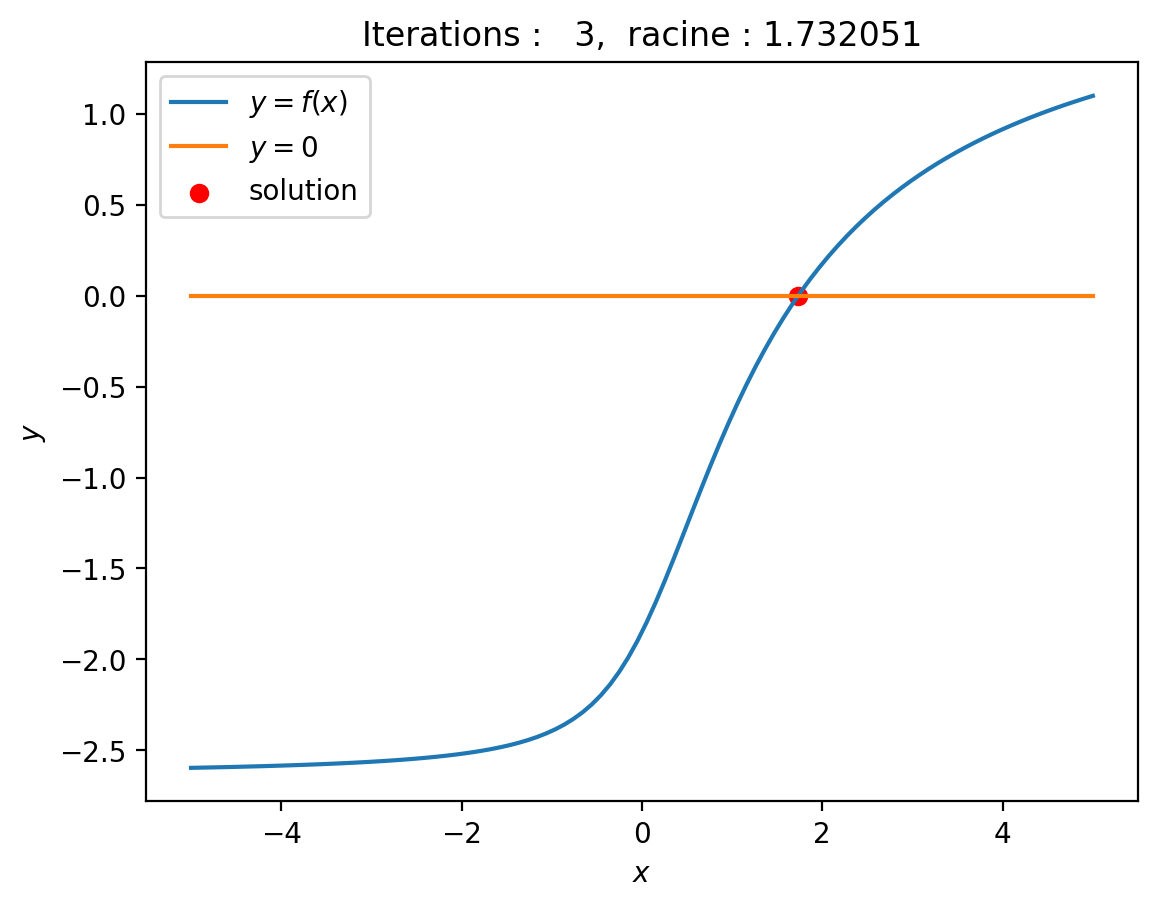

In [9]:
x0,  tol, iterMax = 0, 1e-9, 500 
x= np.linspace(-5,5, 100)

plt.plot(x, f(x), label = "$y = f(x)$")

plt.plot(x, 0 * x, label = "$y = 0$")

x_, niter, _ =  Newton3(f, fprime, x0, tol, iterMax)

plt.scatter(x_, f(x_), color="red", label="solution")
plt.legend()
plt.title("Iterations : {:3d},  racine : {:8.6f}".format(niter, x_))
plt.xlabel("$x$")
plt.ylabel("$y$")
plt.show()


#### Question 2-2-3 : Validations 2/3 (ordre de convergence)

En utilisant une technique de votre choix, déterminer numériquement l'ordre de convergence de cette 
méthode de Newton modifiée.

On remarquera que la solution exacte de $f(x) = 0$  est $x^* = \sqrt{3}$.

Pour simplifier le calul ou néviter des valeurs trop proches de $0$ pénalisantes pour les logarithmes, on pourra au choix

1. soit prendre $x_0 = 5$ dans la génération de la suite permettant de calculer l'ordre de convergence,en prenant soin d'éliminer le dernier élément de la suite (qui serait ici beacoup trop proche la solution)
2. soit utiliser un autre problème de son choix: par example  $ f(x) = e^x -1$  sur $[-1,1]$, avec $x_0 =-0.5, x^* =0$.  



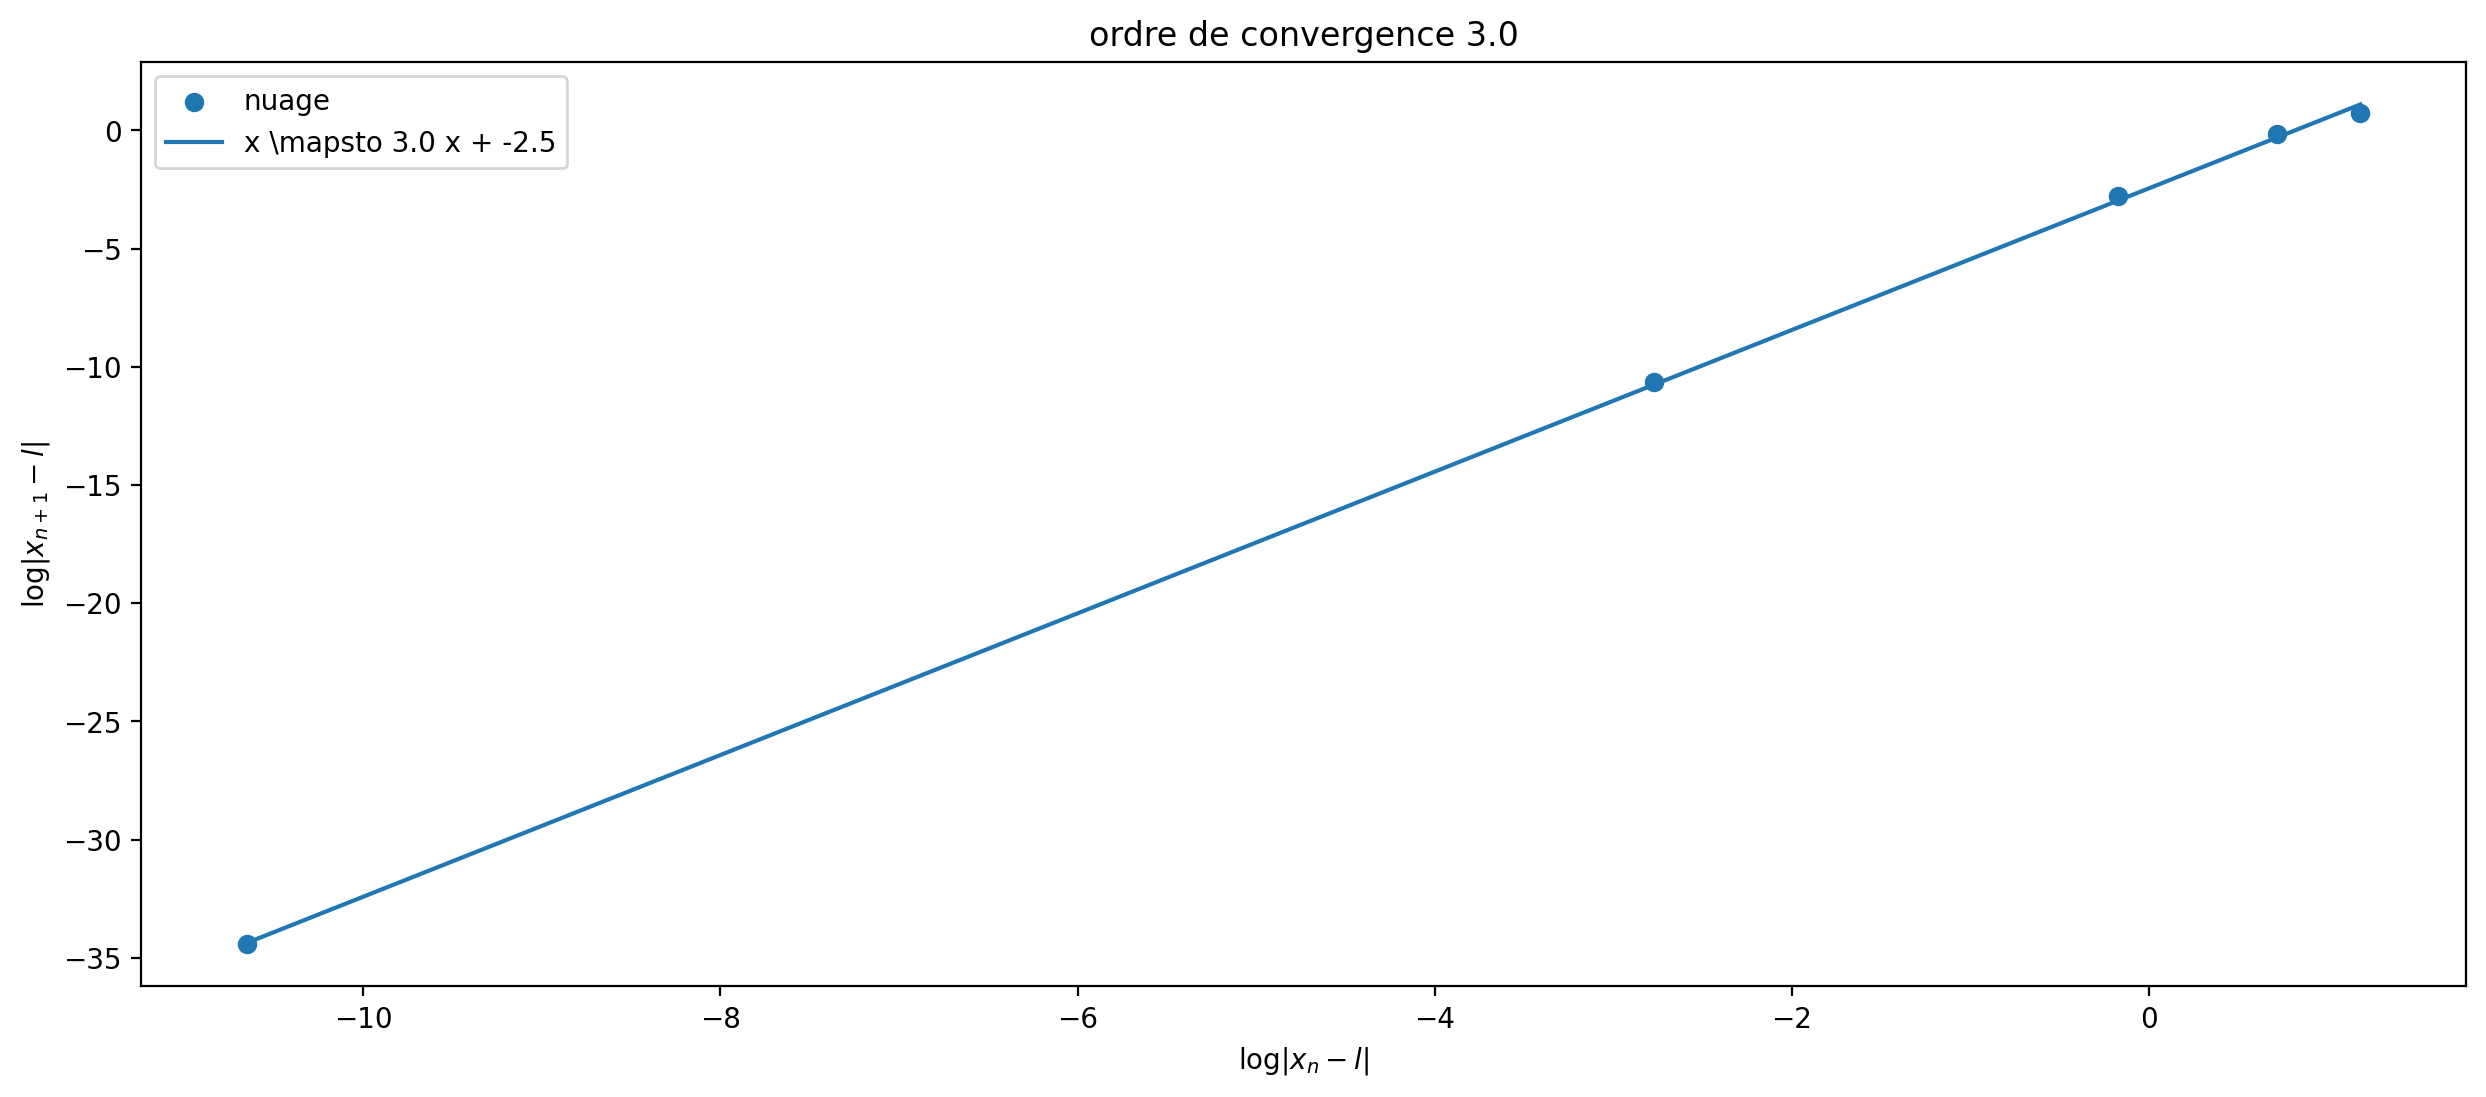

In [11]:
## méthode 1:
xlim, niter, xL = Newton3(f, fprime, x0=5,tol=1.e-32, iterMax=5000)
lim = np.sqrt(3)
fig = plt.figure(figsize=(15, 6))
ax = fig.add_subplot(1, 1, 1)
eL = np.abs(xL[:-1] - lim)
eLx = np.log(eL[0:-1])
eLy = np.log(eL[1:])
a, b = np.polyfit(eLx, eLy,1)
ax.scatter(eLx, eLy, label = "nuage")
ax.plot(eLx, eLx * a + b, label="x \mapsto {:3.2} x + {:3.2}".format(a,b))
ax.set_xlabel("$\log|x_n - l|$")
ax.set_ylabel("$\log|x_{n+1} - l|$")
ax.legend()
ax.set_title("ordre de convergence {:3.2}".format(a))
plt.show()



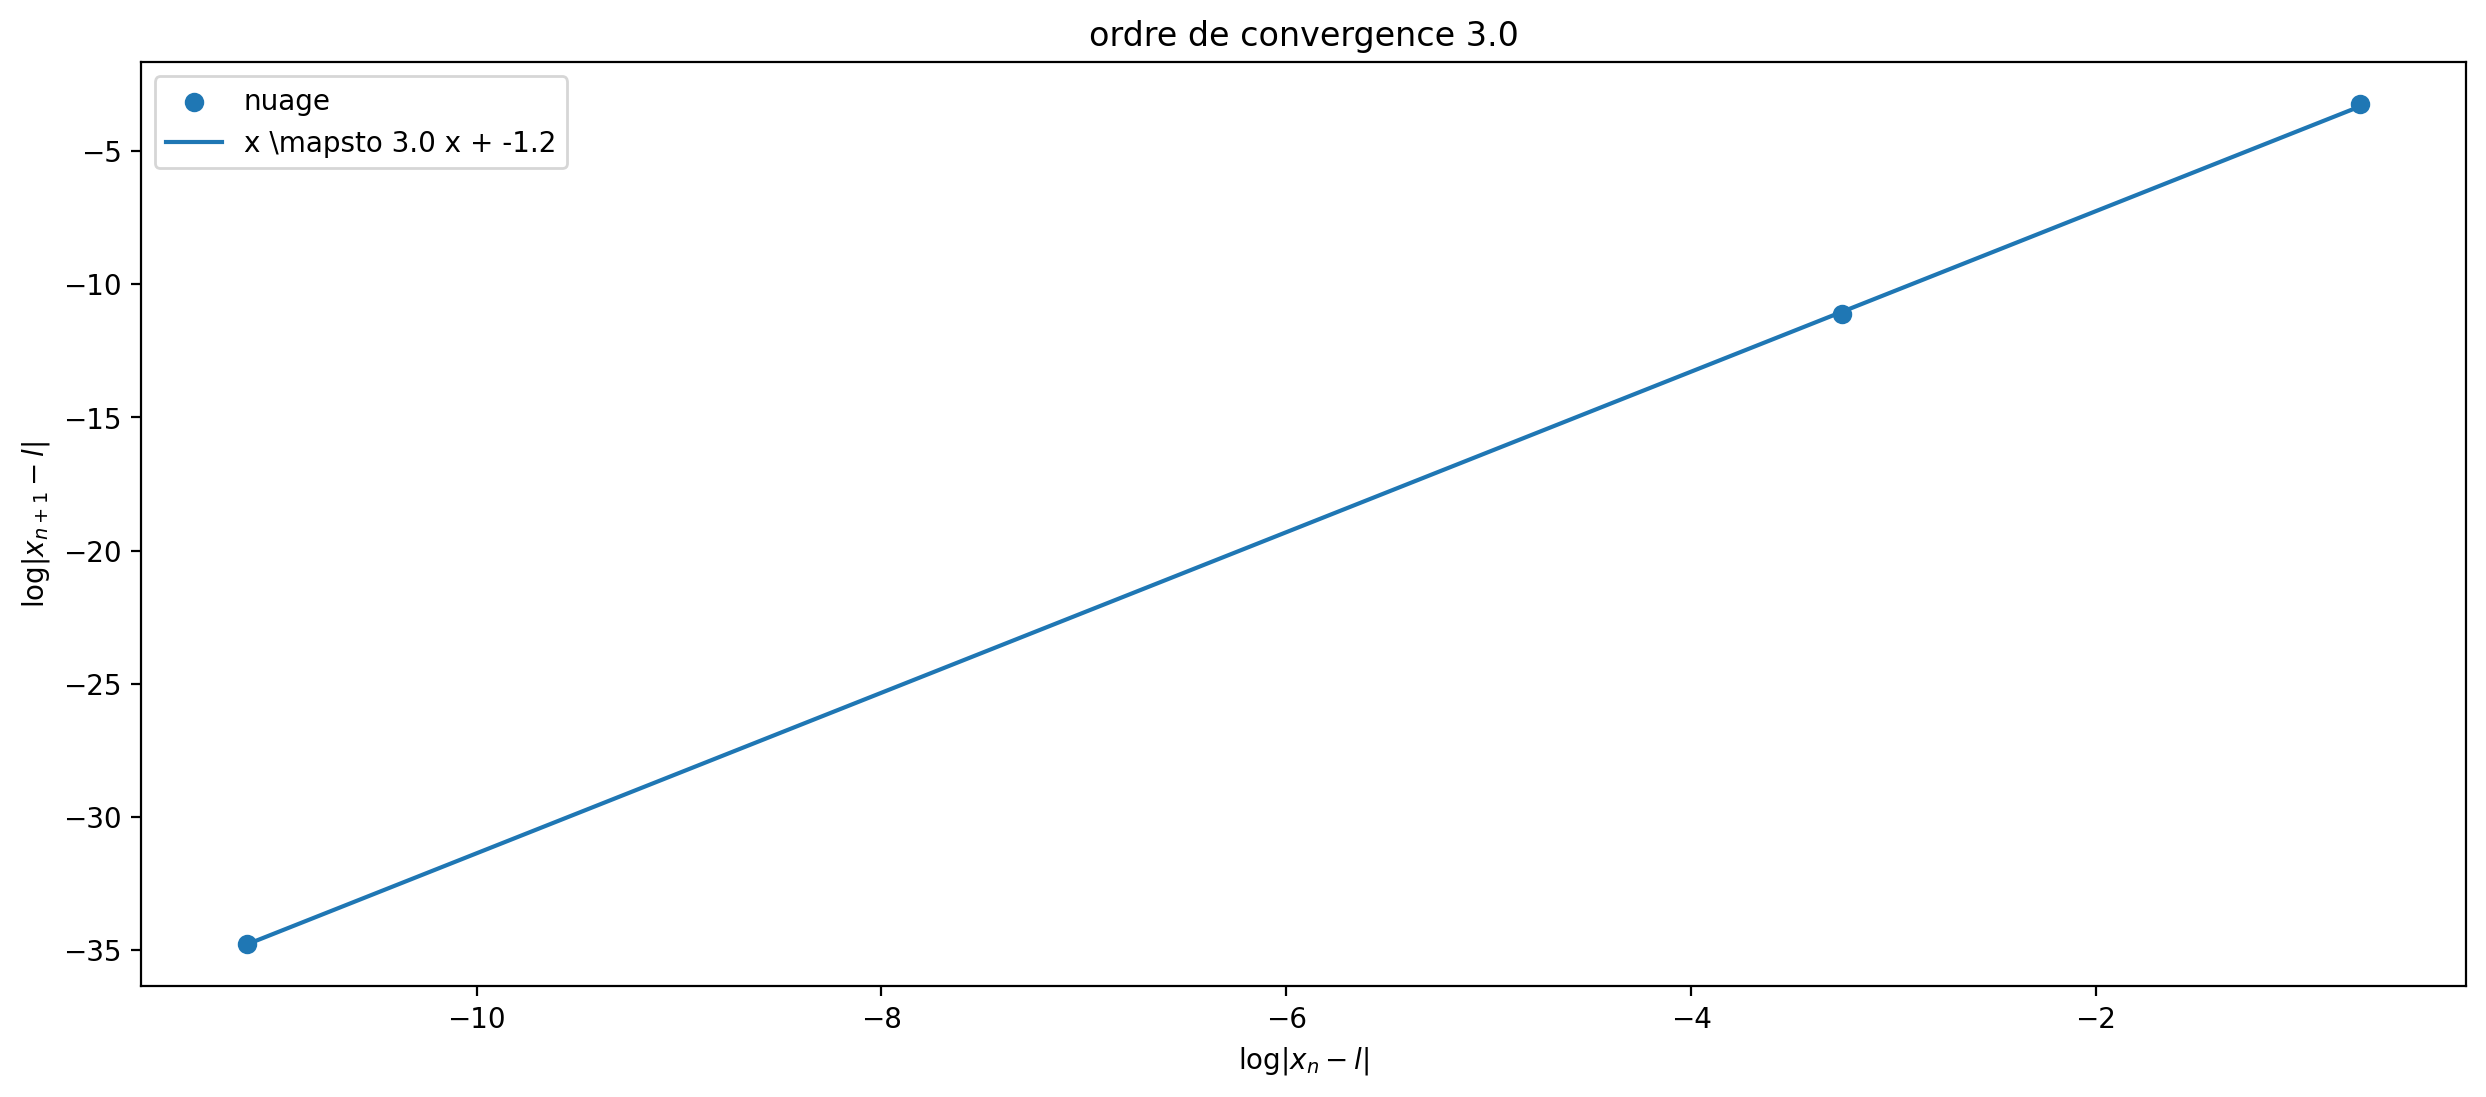

In [12]:
## méthode 2:
xlim, niter, xL = Newton3(lambda x: np.exp(x) -1, lambda x: np.exp(x), x0=-0.5,tol=1.e-16, iterMax=5000)
lim = 0
fig = plt.figure(figsize=(15, 6))
ax = fig.add_subplot(1, 1, 1)
eL = np.abs(xL[:-1] - lim)
eLx = np.log(eL[0:-1])
eLy = np.log(eL[1:])
a, b = np.polyfit(eLx, eLy,1)
ax.scatter(eLx, eLy, label = "nuage")
ax.plot(eLx, eLx * a + b, label="x \mapsto {:3.2} x + {:3.2}".format(a,b))
ax.set_xlabel("$\log|x_n - l|$")
ax.set_ylabel("$\log|x_{n+1} - l|$")
ax.legend()
ax.set_title("ordre de convergence {:3.2}".format(a))
plt.show()

In [6]:
# Méthode 3 
# On peut utiliser TraquerOrdre(xn, lim=0.0, ax=None, title='', suitename='u', precision_machine = 1e-16)
#Vu en TD

#### Question 2-2-4 : Validations 3/3 (ordre de convergence en situation de racine double)

**Question 2-2-4-1** Déterminer l'ordre de convergence de la méthode lorsqu'on l'applique pour détermine la racine double $x^* =0$ de $f(x) = e^x - x -1$. On prendra encore $x_0 = -0.5$.


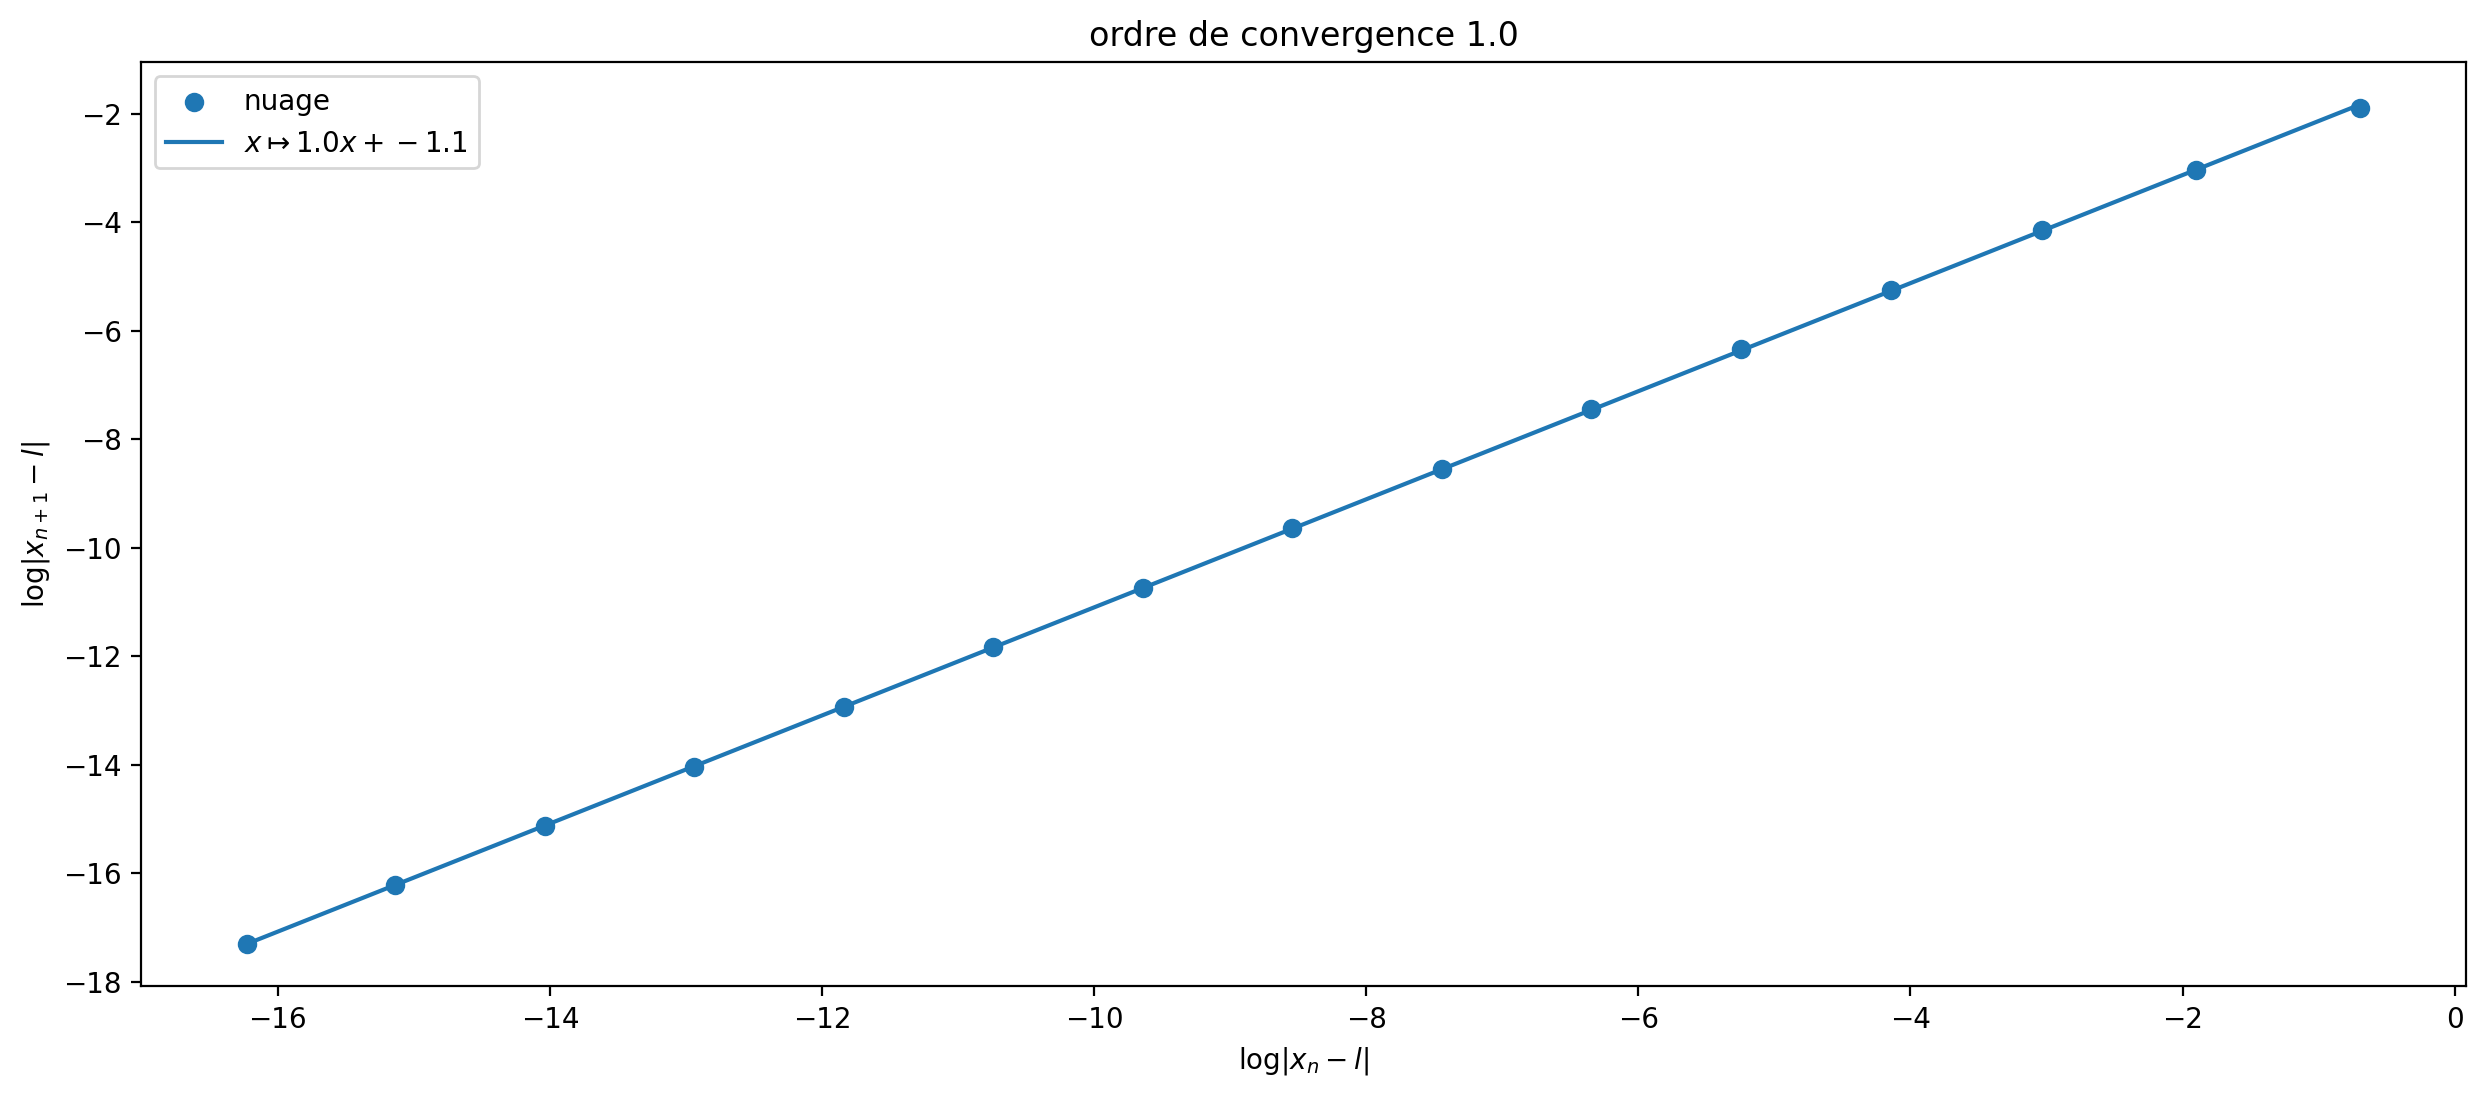

In [13]:
xlim, niter, xL = Newton3(lambda x: np.exp(x) -x -1, lambda x: np.exp(x) -1, x0=-0.5,tol=1.e-16, iterMax=5000)
lim = 0
fig = plt.figure(figsize=(15, 6))
ax = fig.add_subplot(1, 1, 1)
eL = np.abs(xL[:-1] - lim)
eLx = np.log(eL[0:-1])
eLy = np.log(eL[1:])
a, b = np.polyfit(eLx, eLy,1)
ax.scatter(eLx, eLy, label = "nuage")
ax.plot(eLx, eLx * a + b, label="$x \mapsto {:3.2} x + {:3.2}$".format(a,b))
ax.set_xlabel("$\log|x_n - l|$")
ax.set_ylabel("$\log|x_{n+1} - l|$")
ax.legend()
ax.set_title("ordre de convergence {:3.2}".format(a))
plt.show()


**Question 2-2-4-2 (A faire ceci  sur la copie)**

1. Le résultat était-il prévisible ? 

2. Saurez-vous modifier la méthode pour gérer ce cas de racine double ?

3. Si oui, quel ordre de convergence espère-t-on obtenir ?  

**Question 2-2-4-3** Si vous pouvez modifier la méthode `Newton3`,  désignez la par `Newton3RacineDouble` et mettez la dans la cellule ci-dessous et valider la.


In [14]:
# REPONSE ICI  AJOUTER  DES CELLULES SI NECESSAIRE 

def Newton3RacineDouble(f, fprime, x0, tol, iterMax):
    '''
    DOCUMENTATION ICI
    '''
    x = x0
    niter = 0
    xL = [x]
    fx = f(x)
    fpx = fprime(x)
    while np.abs(fx) > tol and niter < iterMax:
        x = x - fx /(fpx/4 + 3 * fprime(x - (2/3) * 2*fx/fpx )/4)
        xL.append(x)
        fx = f(x)
        fpx = fprime(x)
        niter += 1
    return x, niter, np.array(xL)


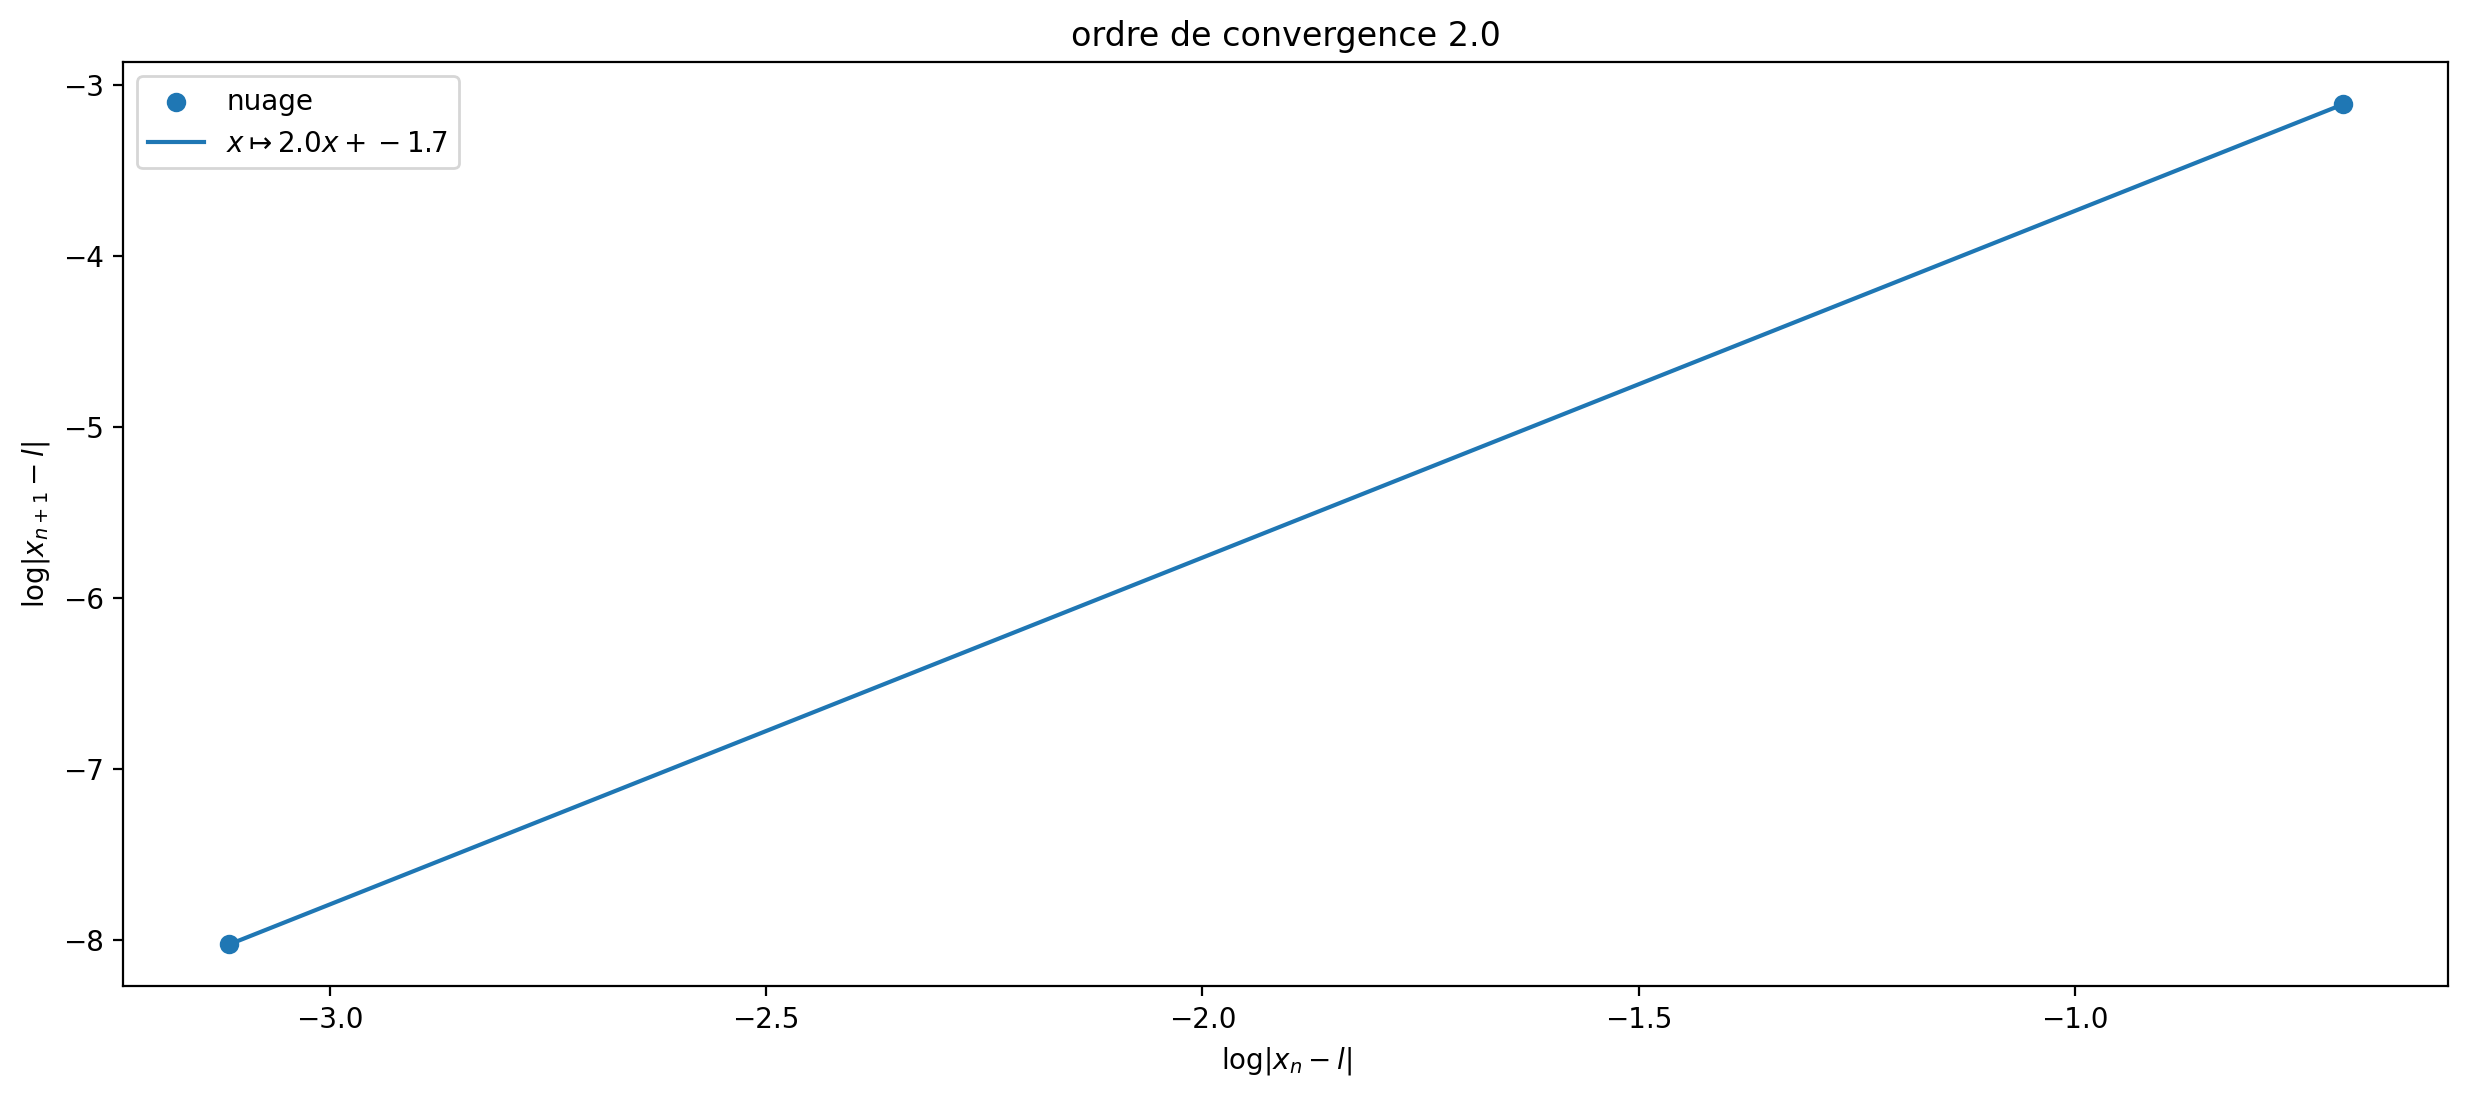

In [15]:
xlim, niter, xL = Newton3RacineDouble(lambda x: np.exp(x) -x -1, lambda x: np.exp(x) -1, x0=-0.5,tol=1.e-16, iterMax=5000)
lim = 0
fig = plt.figure(figsize=(15, 6))
ax = fig.add_subplot(1, 1, 1)
eL = np.abs(xL[:-1] - lim)
eLx = np.log(eL[0:-1])
eLy = np.log(eL[1:])
a, b = np.polyfit(eLx, eLy,1)
ax.scatter(eLx, eLy, label = "nuage")
ax.plot(eLx, eLx * a + b, label="$x \mapsto {:3.2} x + {:3.2}$".format(a,b))
ax.set_xlabel("$\log|x_n - l|$")
ax.set_ylabel("$\log|x_{n+1} - l|$")
ax.legend()
ax.set_title("ordre de convergence {:3.2}".format(a))
plt.show()
